# 1. BigQuery Connection & Data Retrieval

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from google.colab import auth
from google.cloud import bigquery

# Authenticate User and Import Libraries
auth.authenticate_user()

# Initialize BigQuery Client
PROJECT_ID = "data-analytics-mate"
client = bigquery.Client(project=PROJECT_ID)

In [2]:
# Define SQL Query
query = """
SELECT
s.date AS order_date,
s.ga_session_id AS session_id,
sp.continent AS continent,
sp.country AS country,
sp.device AS device,
sp.browser AS browser,
sp.mobile_model_name AS device_model_name,
sp.operating_system AS operating_system,
sp.language AS browser_language,
sp.name AS traffic_source_information,
sp.channel AS traffic_channel,
acc.id AS registered_user_id,
acc.is_verified AS is_email_confirmed,
acc.is_unsubscribed AS is_newsletter_subscribed,
p.category AS product_category,
p.name AS product_name,
p.price AS price,
p.short_description AS product_description
FROM `data-analytics-mate.DA.session` s
LEFT JOIN `data-analytics-mate.DA.session_params` sp
    ON s.ga_session_id = sp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.order` o
    ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` p
    ON o.item_id = p.item_id
LEFT JOIN `data-analytics-mate.DA.account_session` acs
    ON s.ga_session_id = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` acc
    ON acs.account_id = acc.id
"""

# Load BigQuery results into a Pandas DataFrame
df = client.query(query).to_dataframe()


# 2. Data Cleaning & Preprocessing

In [3]:
# Convert data types
df['order_date'] = pd.to_datetime(df['order_date'])
df['is_email_confirmed'] = df['is_email_confirmed'].astype('boolean')
df['is_newsletter_subscribed'] = df['is_newsletter_subscribed'].astype('boolean')

cols_to_convert = ['session_id', 'registered_user_id']
for col in cols_to_convert:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace({'nan': None, '<NA>': None, 'None': None})

In [4]:
# from google.colab import files

# df.to_csv('cleaned_dataset.csv', index=False)

# files.download('cleaned_dataset.csv')

# 3. Dataset Summary & Overview

In [5]:
# Total number of columns
num_cols = df.shape[1]
print(f"Total number of columns: {num_cols}")

# Number of numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
print(f"\nNumber of numeric columns: {len(numeric_cols)}")
print("\nList of numeric columns:")
for col in numeric_cols:
    print(f"- {col}")

# Number of category columns
category_cols = df.select_dtypes(include=['object', 'category', 'string', 'boolean']).columns.tolist()
print(f"\nNumber of category columns: {len(category_cols)}")
print("\nList of category columns:")
for col in category_cols:
    print(f"- {col}")

# Number of date and time columns
date_cols = df.select_dtypes(include=['datetime64']).columns.tolist()
print(f"\nNumber of date and time columns: {len(date_cols)}")
print("\nList of date and time columns:")
for col in date_cols:
    print(f"- {col}")

# Total number of unique sessions
unique_session = df['session_id'].nunique()
print(f"\nTotal number of unique sessions: {unique_session}")

# Date range
print(f"\nDate range from {df['order_date'].min()} to {df['order_date'].max()}")

# Summary of missing values
print("\n--- Total of missing values ---")
print(df.isna().sum())
print("\n--- Percentage of missing values (%) ---")
print((df.isna().sum() / df.shape[0] * 100).round(2))

Total number of columns: 18

Number of numeric columns: 1

List of numeric columns:
- price

Number of category columns: 16

List of category columns:
- session_id
- continent
- country
- device
- browser
- device_model_name
- operating_system
- browser_language
- traffic_source_information
- traffic_channel
- registered_user_id
- is_email_confirmed
- is_newsletter_subscribed
- product_category
- product_name
- product_description

Number of date and time columns: 1

List of date and time columns:
- order_date

Total number of unique sessions: 349545

Date range from 2020-11-01 00:00:00 to 2021-01-31 00:00:00

--- Total of missing values ---
order_date                         0
session_id                         0
continent                          0
country                            0
device                             0
browser                            0
device_model_name                  0
operating_system                   0
browser_language              114266
traffic_source_in

1. **Technical Context (Data Engineering & SQL)**
* Base Table & LEFT JOIN Structure:The query uses DA.session (s) as its base table, sequentially joining 5 secondary tables. The use of LEFT JOIN ensures that all web sessions are preserved, regardless of whether specific actions/events recorded in downstream tables took place.
* Mechanism Behind Missing Values:
  * Product & Order Data (product_*, price ~90.4% missing): Results from the relational chain session $\rightarrow$ order $\rightarrow$ product. If a session did not produce an order, joining on ga_session_id produces NULL across all transactional and product fields.
  * User Account Data (registered_user_id, is_* ~92.0% missing): Results from the relational chain session $\rightarrow$ account_session $\rightarrow$ account. The absence of a matching record in the bridge table account_session means the session was not linked to an account_id, populating account-level attributes with NULL.
* Data Loss Prevention:Applying a chained LEFT JOIN prevents the loss
of the overall session population (the denominator), which would have occurred had an INNER JOIN been used.
2. **Business Context (E-commerce Analytics)**
* Conversion Funnel Evaluation:
~90.4% missing values in order and product tables indicate that ~90.4% of all sessions were purely browsing intent. The overall Conversion Rate (CR) stands at ~9.6% (purchases occurred in 9.6% of sessions), which represents a strong performance for an e-commerce platform.
* User Segmentation (Guest vs. Registered):
~92.0% missing values in the account relation reveal that the vast majority of website traffic is generated by unregistered/guest users. Only ~8% of sessions were tied to an identified user account.
* Web Analytics (browser_language ~32.7% missing):
Missing values in the session_params table for browser language are due to client-side privacy controls (e.g., HTTP header suppression via ad-blockers, private browsing modes, or device restrictions).

# 4. Exploratory Data Analysis (EDA)

### 4.1. Geographical revenue distribution

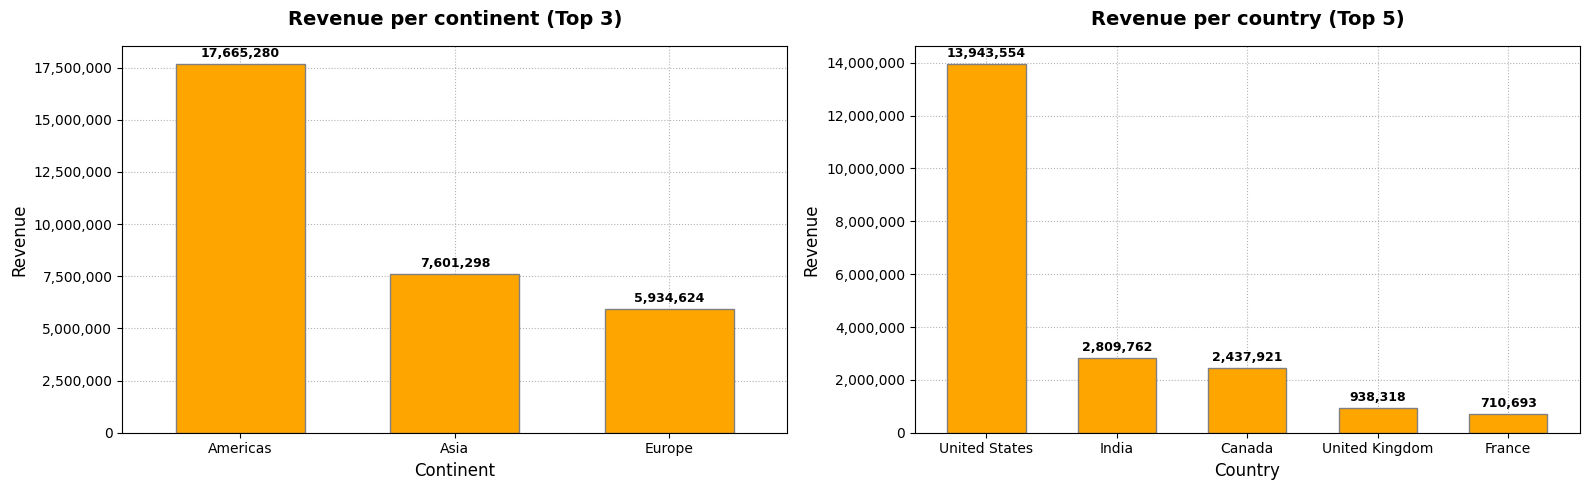

In [6]:
# Aggregate total revenue by continent and filter the Top 3
continent_sales = df.groupby('continent')['price'].sum().reset_index()
continent_sales.sort_values(by='price', ascending=False, inplace=True)
top3_continent_sales = continent_sales.head(3)

# Aggregate total revenue by country and filter the Top 5
country_sales = df.groupby('country')['price'].sum().reset_index()
country_sales.sort_values(by='price', ascending=False, inplace=True)
top5_country_sales = country_sales.head(5)

# Initialize a 1x2 subplot layout for side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Create bar plot for Top 3 continent by revenue
top3_continent_sales.plot(
    x='continent',
    y='price',
    kind='bar',
    color=['orange'],
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax1
)

# Settings for left bar plot
ax1.set_xlabel('Continent', fontsize=12)
ax1.set_ylabel('Revenue', fontsize=12)
ax1.set_title("Revenue per continent (Top 3)", fontsize=14, fontweight='bold', pad=15)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax1.tick_params(axis='x', rotation=0)
ax1.grid(True, linestyle=':', alpha=0.6, color='gray')
ax1.set_axisbelow(True)
ax1.bar_label(ax1.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Create bar plot for Top 5 countries by revenue
top5_country_sales.plot(
    x='country',
    y='price',
    kind='bar',
    color=['orange'],
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax2
)

# Settings for right bar plot
ax2.set_xlabel('Country', fontsize=12)
ax2.set_ylabel('Revenue', fontsize=12)
ax2.set_title("Revenue per country (Top 5)", fontsize=14, fontweight='bold', pad=15)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax2.tick_params(axis='x', rotation=0)
ax2.grid(True, linestyle=':', alpha=0.6, color='gray')
ax2.set_axisbelow(True)
ax2.bar_label(ax2.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

### 4.2. Geographical order volume

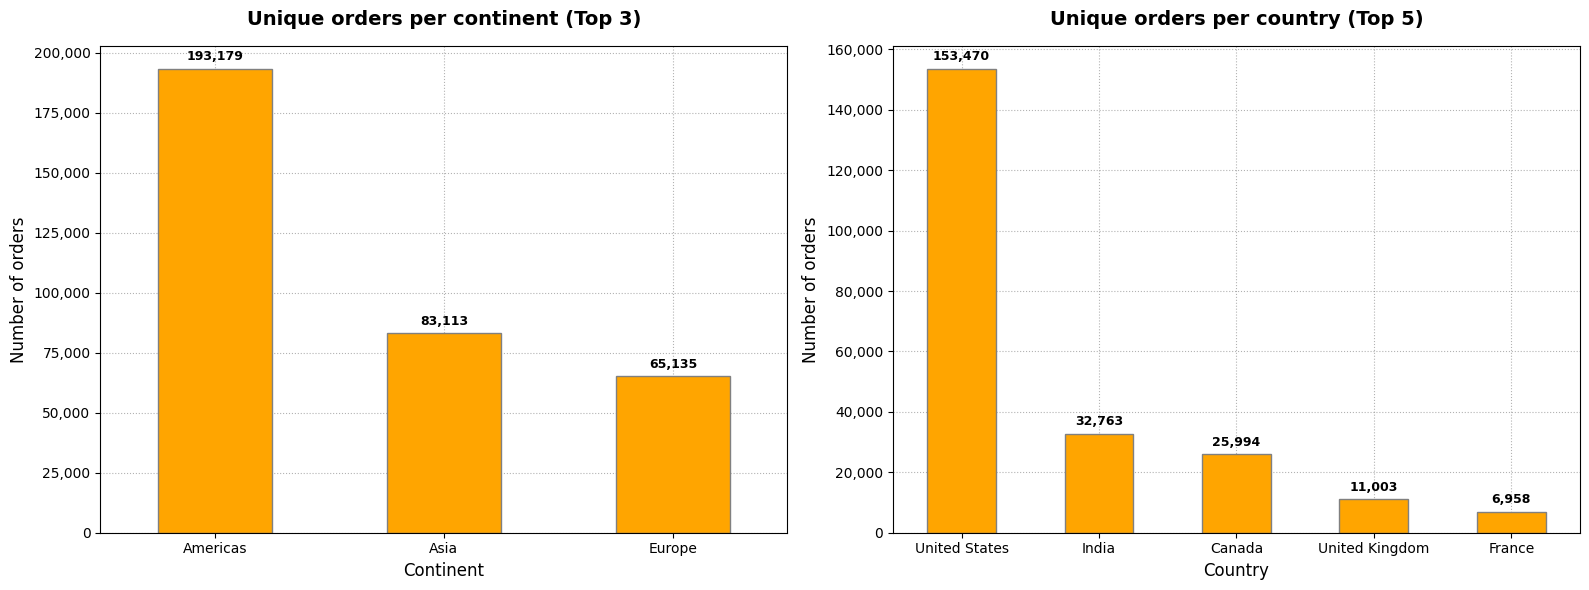

In [7]:
# Aggregate unique orders (session_id) by continent and select Top 3
continent_orders = df.groupby('continent')['session_id'].nunique().reset_index()
continent_orders.sort_values(by='session_id', ascending=False, inplace=True)
top3_continent_orders = continent_orders.head(3)

# Aggregate unique orders (session_id) by country and select Top 5
country_orders = df.groupby('country')['session_id'].nunique().reset_index()
country_orders.sort_values(by='session_id', ascending=False, inplace=True)
top5_country_orders = country_orders.head(5)

# Initialize a 1x2 subplot layout for side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Create bar plot for top 3 continents
top3_continent_orders.plot(
    x='continent',
    y='session_id',
    kind='bar',
    color='orange',
    edgecolor='gray',
    width=0.5,
    legend=False,
    ax=ax1
)

# Settings for left bar plot
ax1.set_xlabel('Continent', fontsize=12)
ax1.set_ylabel('Number of orders', fontsize=12)
ax1.set_title("Unique orders per continent (Top 3)", fontsize=14, fontweight='bold', pad=15)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax1.tick_params(axis='x', rotation=0, labelsize=10)
ax1.grid(True, linestyle=':', alpha=0.6, color='gray')
ax1.set_axisbelow(True)
ax1.bar_label(ax1.containers[0], fmt='{:,.0f}', padding=4, fontsize=9, fontweight='bold')

# Create bar plot for top 5 countries
top5_country_orders.plot(
    x='country',
    y='session_id',
    kind='bar',
    color='orange',
    edgecolor='gray',
    width=0.5,
    legend=False,
    ax=ax2
)

# Settings for right bar plot
ax2.set_xlabel('Country', fontsize=12)
ax2.set_ylabel('Number of orders', fontsize=12)
ax2.set_title("Unique orders per country (Top 5)", fontsize=14, fontweight='bold', pad=15)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax2.tick_params(axis='x', rotation=0, labelsize=10)
ax2.grid(True, linestyle=':', alpha=0.6, color='gray')
ax2.set_axisbelow(True)
ax2.bar_label(ax2.containers[0], fmt='{:,.0f}', padding=4, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

### 4.3. Top 10 product categories by total sales

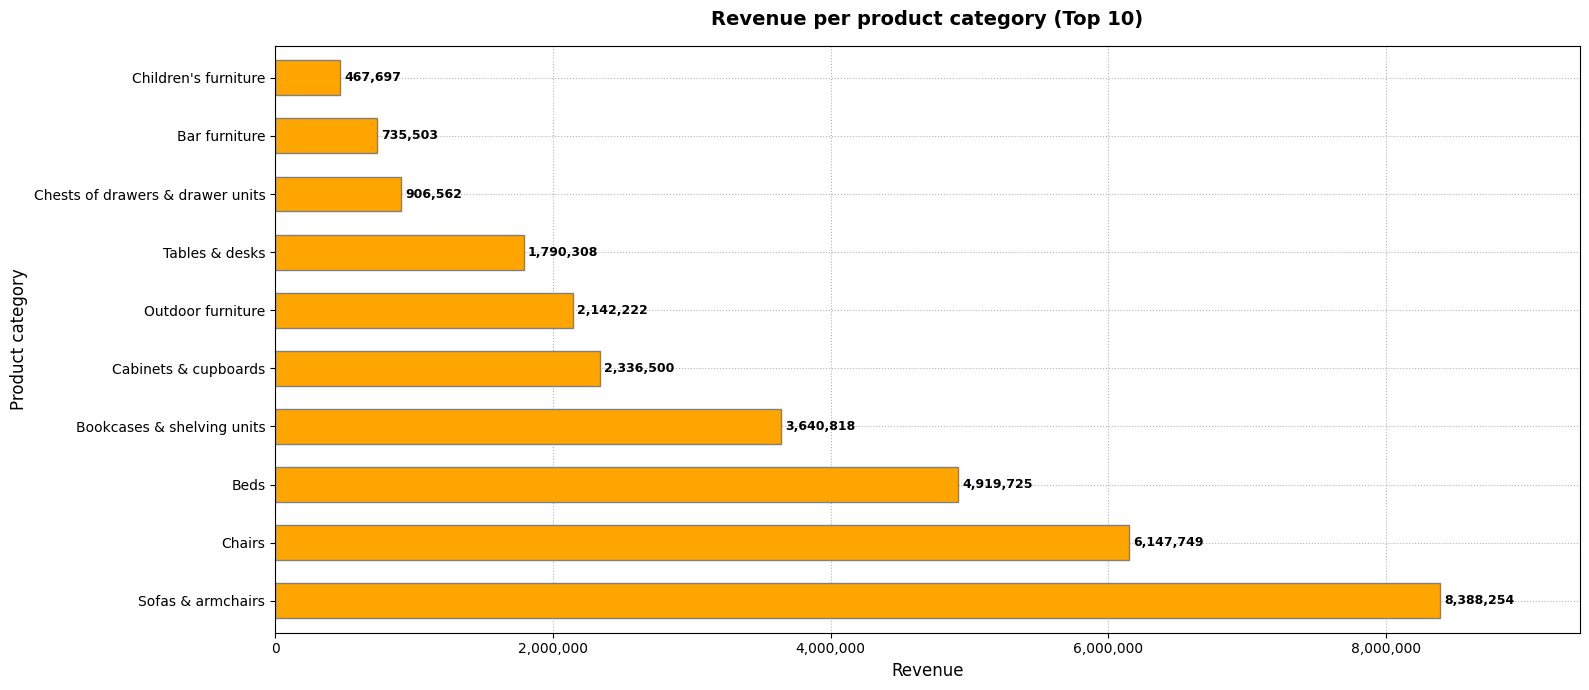

In [8]:
# Aggregate total revenue by product category and filter the Top 10
categories_price = df.groupby('product_category')['price'].sum().reset_index()
categories_price.sort_values(by='price', ascending=False, inplace=True)
top10_categories = categories_price.head(10)

# Create bar plot for Top 10 total revenue by product category
ax = top10_categories.plot(
    x='product_category',
    y='price',
    kind='barh',
    figsize=(16, 7),
    color=['orange'],
    edgecolor='gray',
    width=0.6,
    legend=False
)

# Settings for bar plot
ax.set_xlabel('Revenue', fontsize=12)
ax.set_ylabel('Product category', fontsize=12)
ax.set_title("Revenue per product category (Top 10)", fontsize=14, fontweight='bold', pad=15)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax.grid(True, linestyle=':', alpha=0.6, color='gray')
ax.set_axisbelow(True)
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')
ax.set_xlim(0, top10_categories['price'].max() * 1.12)

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

### 4.4. Product category breakdown for top revenue country

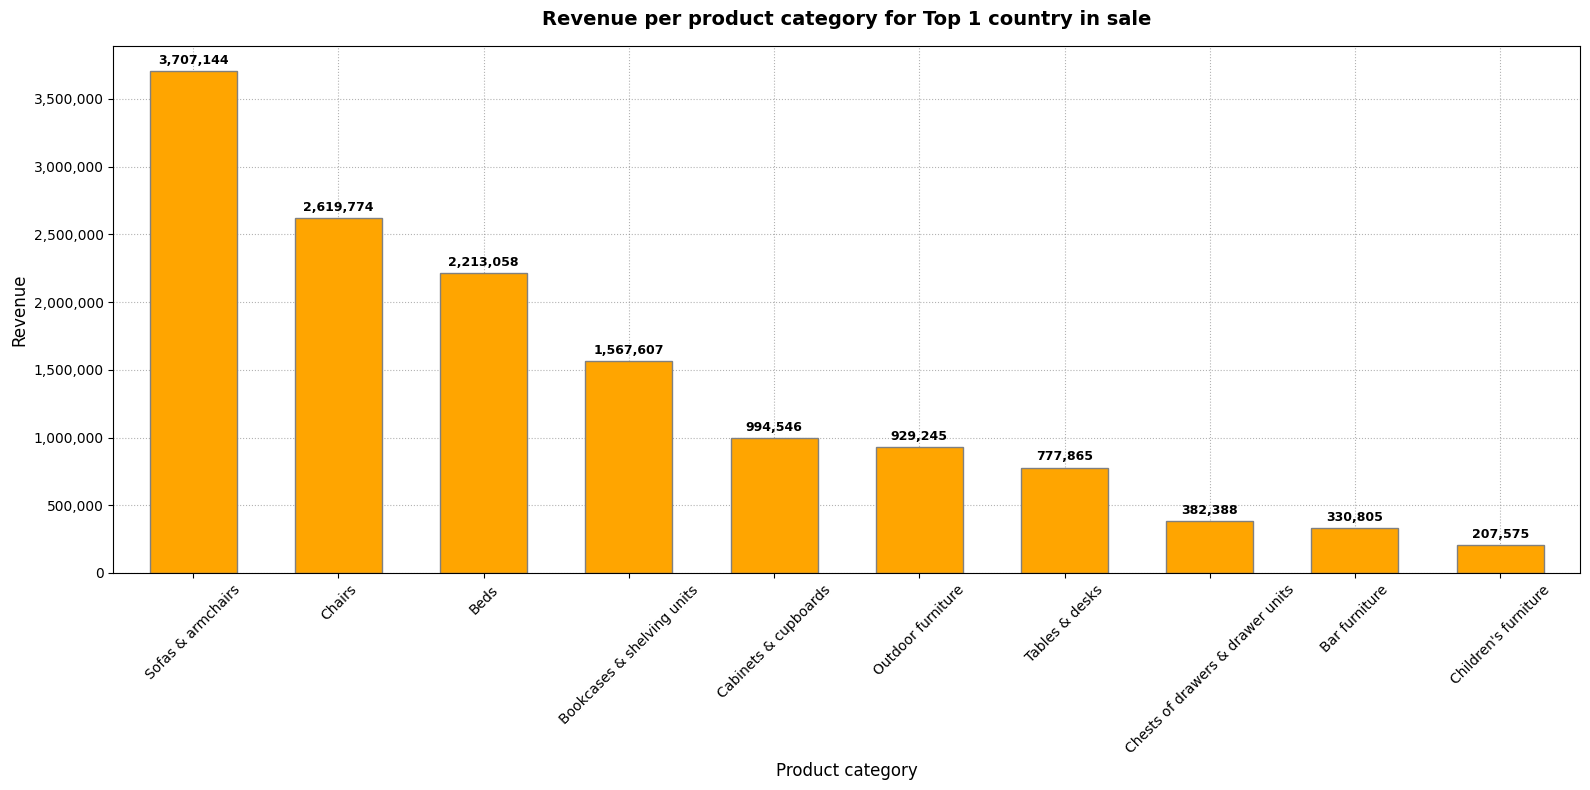

In [9]:
# Aggregate total revenue by country and reset index
country_ranking = df.groupby('country')['price'].sum().reset_index()
country_ranking.sort_values(by='price', ascending=False, inplace=True)

# Extract the top-performing country by revenue (rank 1)
top_country = country_ranking.iloc[0]['country']

# Filter dataset for the top country, aggregate revenue by product category, and retrieve top 10 categories
top_country_categories = (
    df[df['country'] == top_country]
    .groupby('product_category')['price']
    .sum()
    .reset_index()
    .sort_values(by='price', ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(16, 8))

# Create bar plot for revenue by product category for Top 1 in sale
top_country_categories.plot(
    x='product_category',
    y='price',
    kind='bar',
    color='orange',
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax
)

# Settings for bar plot
ax.set_xlabel('Product category', fontsize=12)
ax.set_ylabel('Revenue', fontsize=12)
ax.set_title("Revenue per product category for Top 1 country in sale", fontsize=14, fontweight='bold', pad=15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax.tick_params(axis='x', rotation=45, labelsize=10)
ax.grid(True, linestyle=':', alpha=0.6, color='gray')
ax.set_axisbelow(True)
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

### 4.5. Revenue breakdown by device and device model

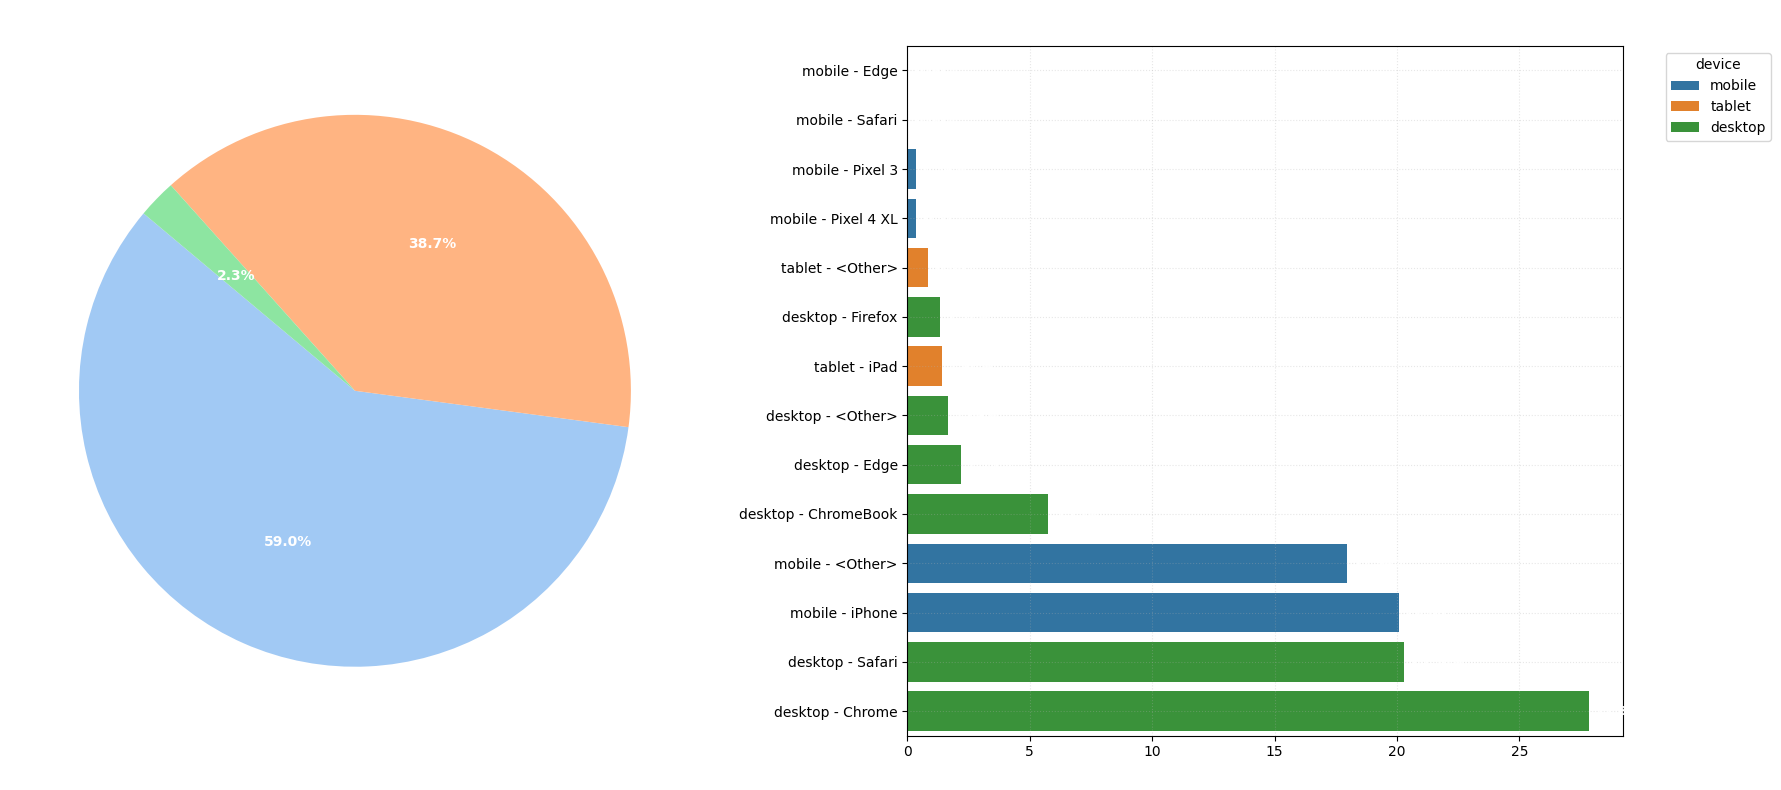

In [10]:
# Aggregate total revenue by device and calculate percentage value
device_groupby = df.groupby('device')['price'].sum().reset_index()
total_price = df['price'].sum()
device_groupby['pct_total_price'] = (device_groupby['price'] / total_price * 100).round(2)
device_groupby.sort_values(by='price', ascending=False, inplace=True)

# Aggregate total revenue by device, device_model_name and calculate percentage value
device_model_groupby = df.groupby(['device','device_model_name'])['price'].sum().reset_index()
device_model_groupby['pct_total_price'] = (device_model_groupby['price'] / total_price * 100).round(2)
device_model_groupby.sort_values(by='price', ascending=True, inplace=True)

# Create uniqe label for mobile - Safari, desktop - Safari
device_model_groupby['device_and_model'] = (
    device_model_groupby['device'] + " - " + device_model_groupby['device_model_name']
)

# Sorted data by ascending
df_sorted = device_model_groupby.sort_values(by='pct_total_price', ascending=True)

# Create a 1x2 grid for side-by-side plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
colors = sns.color_palette('pastel')

# 1. Pie chart (left)
ax1.pie(
    device_groupby['pct_total_price'],
    labels=device_groupby['device'],
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    textprops={'fontsize': 10, 'fontweight': 'bold', 'color': 'white'}
)
ax1.set_title("Revenue by device", fontsize=14, fontweight='bold', pad=15, color='white')

# 2. Seaborn bar plot (right)
sns.barplot(
    data=df_sorted,
    x='pct_total_price',
    y='device_and_model',
    hue='device',
    dodge=False,
    palette='tab10',
    ax=ax2
)

# Add percentage labels to the bar chart (white text for dark background)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f%%', padding=5, color='white', fontsize=9, fontweight='bold')

# Settings for the bar plot
ax2.set_title('Revenue by device and model (%)', fontsize=14, fontweight='bold', pad=15, color='white')
ax2.set_xlabel('Percentage of total revenue (%)', fontsize=11, color='white')
ax2.set_ylabel('Device and model / browser', fontsize=11, color='white')
ax2.grid(True, linestyle=':', alpha=0.3)

# Move legend outside the plot to prevent overlapping
ax2.legend(title='device', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout to prevent overlapping and display both plots
plt.tight_layout()
plt.show()

### 4.6. Revenue breakdown by traffic channel


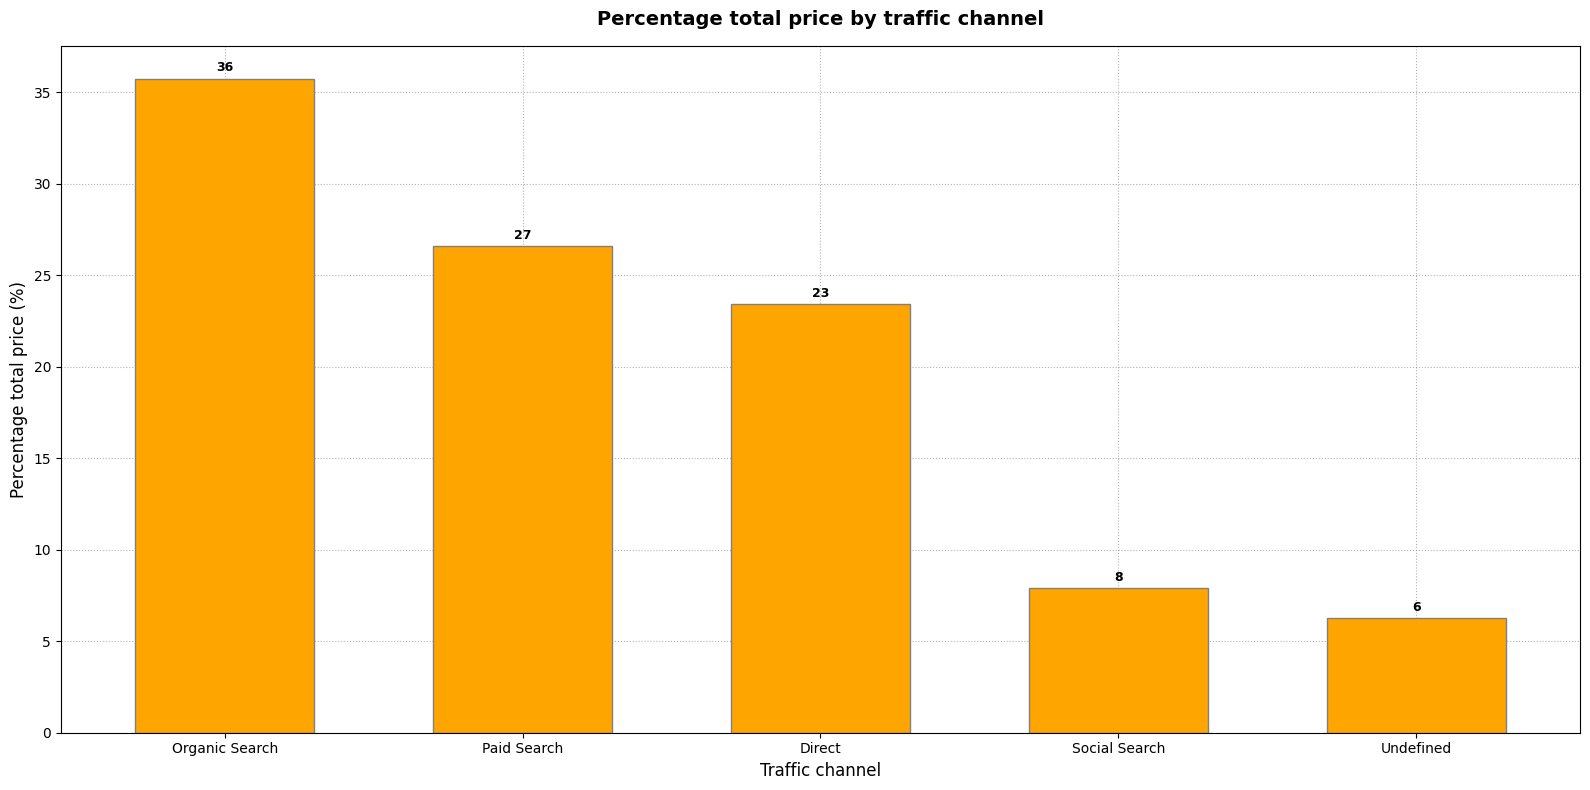

In [11]:
# Aggregate total revenue by traffic_channel, total revenue and calculated percentage
traffic_source_groupby = df.groupby('traffic_channel')['price'].sum().reset_index().sort_values(by='price', ascending=False)
total_price = df['price'].sum()
traffic_source_groupby['pct_total_price'] = (traffic_source_groupby['price'] / total_price * 100).round(2)

fig, ax = plt.subplots(figsize=(16, 8))

# Create bar plot
traffic_source_groupby.plot(
    x='traffic_channel',
    y='pct_total_price',
    kind='bar',
    color='orange',
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax
)

# Settings for bar plot
ax.set_xlabel('Traffic channel', fontsize=12)
ax.set_ylabel('Percentage total price (%)', fontsize=12)
ax.set_title("Percentage total price by traffic channel", fontsize=14, fontweight='bold', pad=15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax.tick_params(axis='x', rotation=0, labelsize=10)
ax.grid(True, linestyle=':', alpha=0.6, color='gray')
ax.set_axisbelow(True)
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

### 4.7. Registered Users Email Verification Rate

In [12]:
# Aggregate count of total registered users with email verification and percentage
total_registered_user = df['registered_user_id'].nunique()
total_registered_user_with_email = df[df['is_email_confirmed'] == True]['registered_user_id'].nunique()
prc_total_registered_user_with_email = round((total_registered_user_with_email / total_registered_user) * 100, 2)
print(f'Total registered users: {total_registered_user}')
print(f'Total registered users with email confirmed: {total_registered_user_with_email}')
print(f'Percentage of total registered users with email confirmed: {prc_total_registered_user_with_email}%')

Total registered users: 27945
Total registered users with email confirmed: 20036
Percentage of total registered users with email confirmed: 71.7%


### 4.8. Registered Users Non-Subscribers Breakdown

In [13]:
# Aggregate count of total registered users without newsletter subscribed and percentage
total_registered_user = df['registered_user_id'].nunique()
total_registered_user_without_subscribed = df[df['is_newsletter_subscribed'] != True]['registered_user_id'].nunique()
prc_total_registered_user_without_subscribed = round((total_registered_user_without_subscribed / total_registered_user) * 100,2)
print(f'Total registered users: {total_registered_user}')
print(f'Total registered users without newsletter subscribed: {total_registered_user_without_subscribed}')
print(f'Percentage of total registered users without newsletter subscribed: {prc_total_registered_user_without_subscribed}%')

Total registered users: 27945
Total registered users without newsletter subscribed: 23210
Percentage of total registered users without newsletter subscribed: 83.06%


### 4.9. Revenue and orders breakdown by newsletter subscription

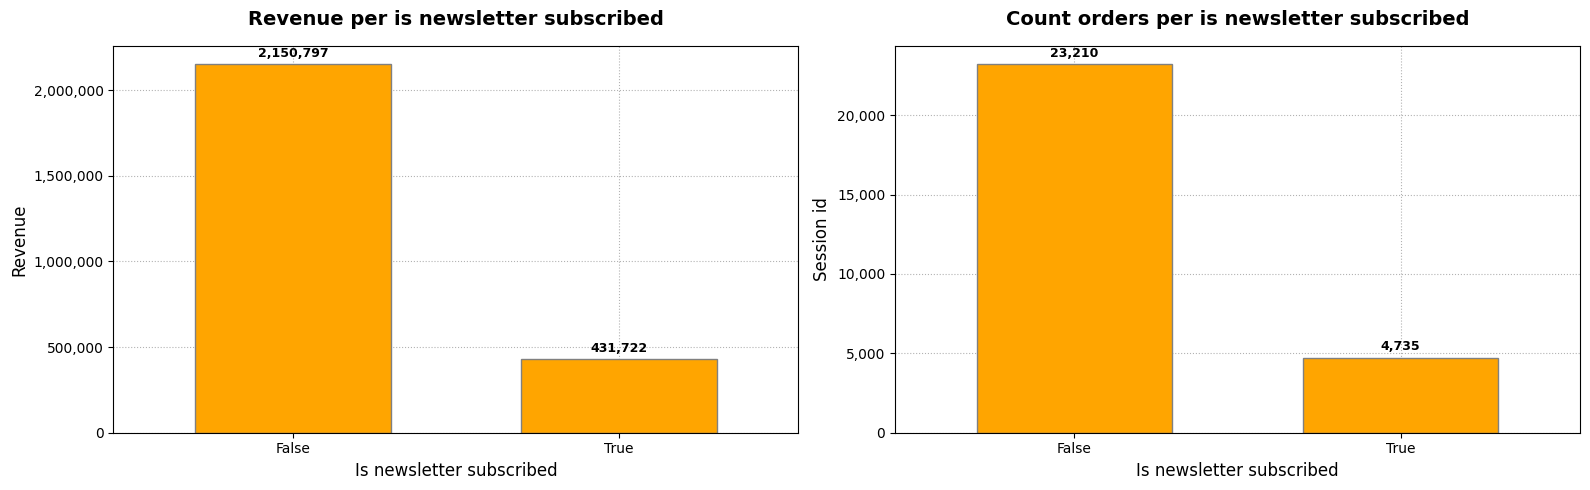

In [14]:
# Aggregate total revenue and count of orders for is newsletter subscribed
sales_by_newsletter = df.groupby('is_newsletter_subscribed')['price'].sum().sort_values(ascending=False)
count_by_newsletter = df.groupby('is_newsletter_subscribed')['session_id'].nunique().sort_values(ascending=False)

# Initialize a 1x2 subplot layout for side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Create left bar plot
sales_by_newsletter.plot(
    x='is_newsletter_subscribed',
    y='price',
    kind='bar',
    color=['orange'],
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax1
)

# Settings for left bar plot
ax1.set_xlabel('Is newsletter subscribed', fontsize=12)
ax1.set_ylabel('Revenue', fontsize=12)
ax1.set_title("Revenue per is newsletter subscribed", fontsize=14, fontweight='bold', pad=15)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax1.tick_params(axis='x', rotation=0)
ax1.grid(True, linestyle=':', alpha=0.6, color='gray')
ax1.set_axisbelow(True)
ax1.bar_label(ax1.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Create right bar plot
count_by_newsletter.plot(
    x='is_newsletter_subscribed',
    y='price',
    kind='bar',
    color=['orange'],
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax2
)

# Settings for right bar plot
ax2.set_xlabel('Is newsletter subscribed', fontsize=12)
ax2.set_ylabel('Session id', fontsize=12)
ax2.set_title("Count orders per is newsletter subscribed", fontsize=14, fontweight='bold', pad=15)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax2.tick_params(axis='x', rotation=0)
ax2.grid(True, linestyle=':', alpha=0.6, color='gray')
ax2.set_axisbelow(True)
ax2.bar_label(ax2.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()


### 4.10. Top countries by Registered Users

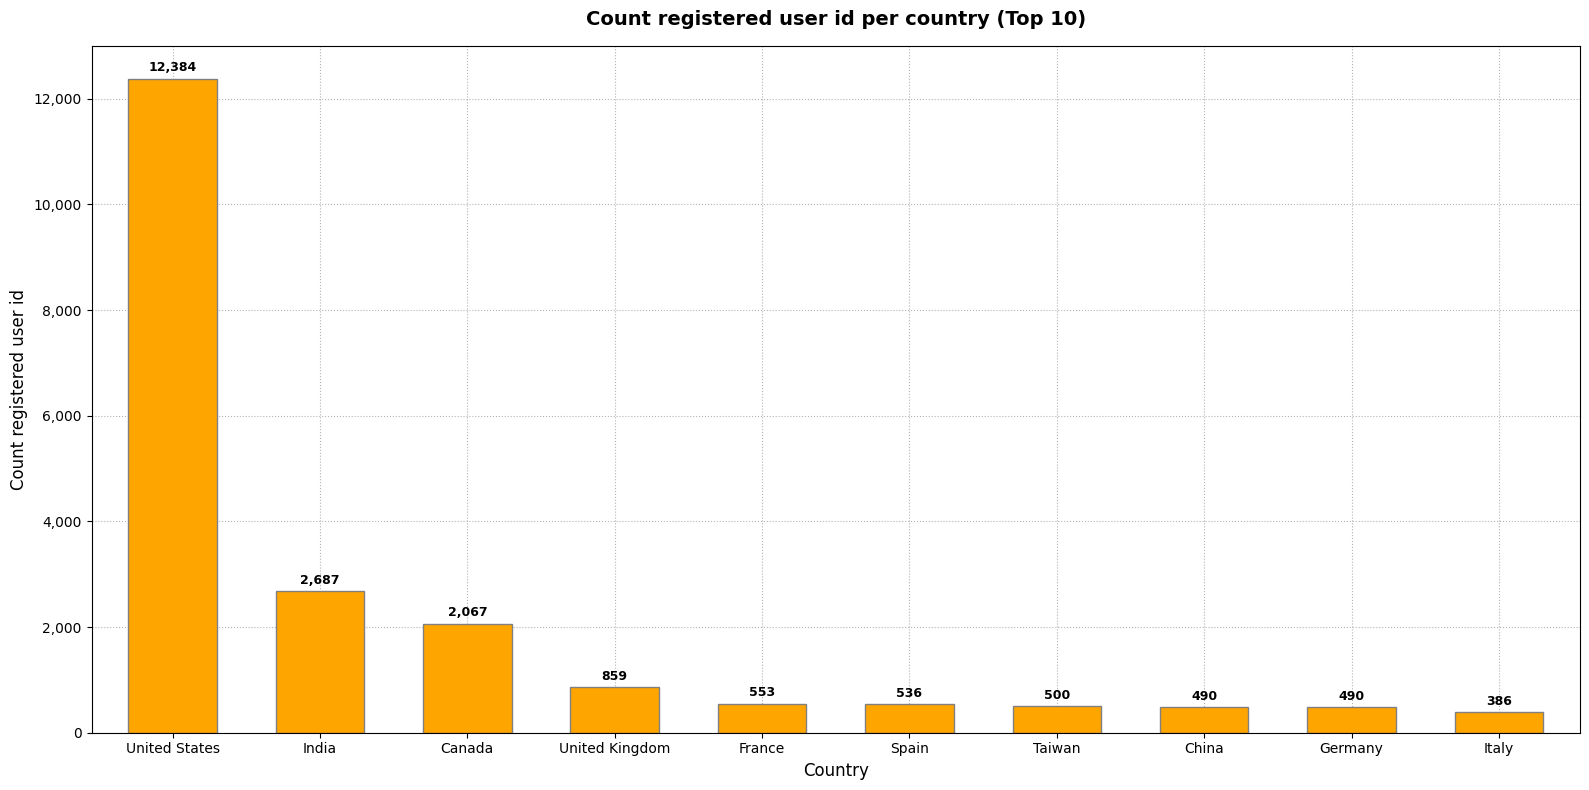

In [15]:
# Aggregate count of registered user per country and sort values descending
count_registered_users_per_country = df.groupby('country')['registered_user_id'].nunique().sort_values(ascending=False)
top_10_countries = count_registered_users_per_country.head(10)

fig, ax = plt.subplots(figsize=(16, 8))

# Create bar plot
top_10_countries .plot(
    x='country',
    y='registered_user_id',
    kind='bar',
    color='orange',
    edgecolor='gray',
    width=0.6,
    legend=False,
    ax=ax
)

# Settings for bar plot
ax.set_xlabel('Country', fontsize=12)
ax.set_ylabel('Count registered user id', fontsize=12)
ax.set_title("Count registered user id per country (Top 10)", fontsize=14, fontweight='bold', pad=15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: "{:,.0f}".format(x)))
ax.tick_params(axis='x', rotation=0, labelsize=10)
ax.grid(True, linestyle=':', alpha=0.6, color='gray')
ax.set_axisbelow(True)
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()
plt.show()

# 5. Sales Dynamics Analysis

[Tableau Dashboard](https://public.tableau.com/views/Portfolioproject1_17868868340750/Dashboard1?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

5.1. Summary

*   **Total Revenue:** The business generated a total of $31,971,731 in revenue across 349,545 orders
*   **Desktop is the primary sales channel:** Desktop devices account for the vast majority of orders at 204,429
*   **Mobile ranks second:** Smartphones generated 137,267 orders
*   **Organic Search:** The most effective acquisition channel, driving 124,425 orders
*   **Paid Search:** The second most important source with 94,341 orders

*   **Pre-holiday peak (December):** Weekly revenue grew rapidly starting in November, reaching its peak in mid-December (the week around December 14, 2020 – exceeding $3.5M in weekly revenue)
*   **Post-holiday slowdown:** A drop in sales is visible following Christmas and New Year's.

*   **Core markets:** Sales are heavily concentrated in North America and Europe
*   **Secondary regions:** Lower activity is visible in South Asia (India) and Australia

5.2. Strategic Recommendations



*   **Optimize the Mobile Funnel:** Given that modern e-commerce typically skews heavily mobile, the gap between Desktop and Mobile here is substantial (204k vs. 137k)


# 6. Pivot table

[Pivot tables](https://public.tableau.com/views/Portfolioproject1_17868868340750/Dashboard2?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

### 6.1. Count session by traffic channel and device

Description: Displays the distribution of user sessions across different traffic channels (e.g., Organic, Paid, Direct) segmented by device type (desktop, mobile, tablet) to highlight key acquisition channels.

Summary

**Desktop drives the highest session volume:**


*   Organic Search on Desktop is the single largest traffic segment (72,622 sessions)
*   Paid Search (55,167) and Direct (47,825) on Desktop follow closely



### 6.2. Top 10 Categories in Top 5 Countries

Description: Ranks the top 10 best-selling product categories within the top 5 generating countries to analyze regional product demand and top revenue drivers.

Summary


**United States is the massive primary market:** Revenue from the US vastly outpaces all other countries. Across every single market (US, UK, India, France, Canada), the top product categories follow the exact same ranking hierarchy:
*   Sofas & armchairs Absolute top seller
*   Chairs
*   Beds
*   Bookcases & shelving



### 6.3. Monthly revenue by continent

Description: Tracks total revenue broken down by geographic continent across months, helping to identify regional sales performance and seasonal trends.

Summary

*   **Americas dominates total volume:** Generated $6.85M in December (peak month)

*   **Holiday seasonality pattern:** Across almost all continents (Americas, Asia, Europe, Oceania, Africa), revenue peaked in December before falling back in January to levels slightly below November

### 6.4. RPS & Revenue by Tech Stack

Description: Provides a detailed technical breakdown of performance metrics (Total Revenue, Total Sessions, and Revenue Per Session) segmented by device, operating system, and browser.

Summary

**High-value tech stack outliers:**


*   Macintosh (browser): Exceptional RPS of $201.62 (though on a low sample size of 49 sessions)

*   Windows (browser): High RPS of $161.63 across 790 sessions

*   Macintosh + Edge (browser): High RPS of $321.03 across 34 sessions

**Mainstream volume drivers maintain stable RPS:**

*   Desktop Chrome users across OS environments consistently generate an RPS around $91.00 – $95.00

*   Mobile iOS Safari users maintain a very steady RPS of $90.84

*   Mobile Android Chrome users hold an RPS of $93.06



### 6.5. Strategic Recommendations

Focus inventory on core categories: Since Sofas & armchairs, Chairs, and Beds generate the bulk of total revenue globally, marketing campaigns and inventory planning should prioritize these top 3 categories

# 7. Statistical analysis of the relationship

### 7.1. Analyze sessions vs revenue correlation

Test statistic and p-value: PearsonRResult(statistic=np.float64(0.7910809164540891), pvalue=np.float64(6.483532312080735e-21))
Test statistic and p-value: SignificanceResult(statistic=np.float64(0.8653062174563682), pvalue=np.float64(9.755923586156614e-29))
Pearson Correlation: 0.7910809164540887
Spearman Correlation: 0.8653062174563682


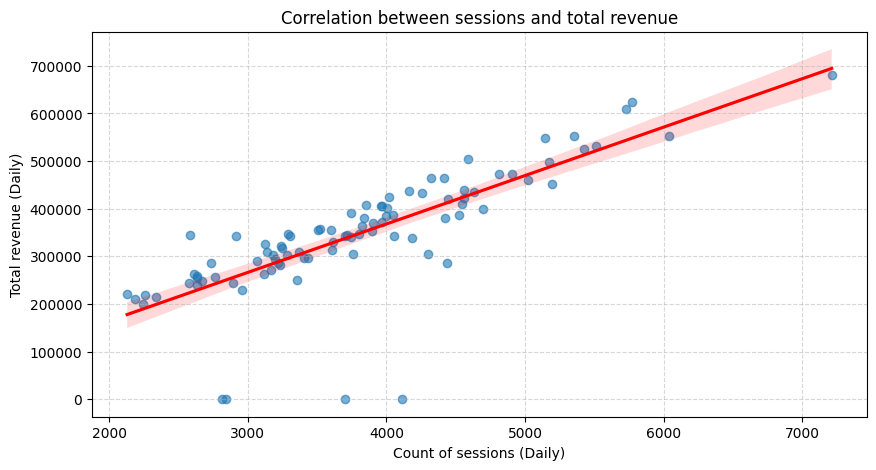

In [16]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# Create a new DataFrame grouped by order date and aggregate session counts and total revenue
df_daily = df.groupby('order_date').agg(cnt_session=('session_id', 'nunique'), total_revenue=('price', 'sum')).reset_index()

# Calculate Pearson and Spearman correlation
pearson_corr = df_daily['cnt_session'].corr(df_daily['total_revenue'], method='pearson')
spearman_corr = df_daily['cnt_session'].corr(df_daily['total_revenue'], method='spearman')

# Calculate p-value
print(f"Test statistic and p-value: {pearsonr(df_daily['cnt_session'], df_daily['total_revenue'])}")
print(f"Test statistic and p-value: {spearmanr(df_daily['cnt_session'], df_daily['total_revenue'])}")

# Print Pearson and Spearman correlation
print(f"Pearson Correlation: {pearson_corr}")
print(f"Spearman Correlation: {spearman_corr}")

# Create a plot
plt.figure(figsize=(10, 5))
sns.regplot(data=df_daily, x='cnt_session', y='total_revenue', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.title('Correlation between sessions and total revenue')
plt.xlabel('Count of sessions (Daily)')
plt.ylabel('Total revenue (Daily)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Summary

Direct Predictability: There is a strong, positive linear relationship between daily session count and total daily revenue. As the number of daily sessions increases, revenue grows proportionally and predictably along the red trend line.

Predictable Scaling: On high-traffic days (5,000 to 7,000+ sessions), daily revenue scales smoothly up to $500k–$700k without noticeable diminishing returns.

Strategic Recommendations

Focus on Traffic Acquisition: Since revenue scales linearly with traffic, marketing investments aimed at increasing qualified session volume (SEO, SEM) are highly reliable drivers for revenue growth.

### 7.2. ANOVA Test for daily sales by continent in Top3

In [22]:
import pandas as pd
from scipy import stats

# Separate top 3 continents and create new dataframe
top3_continents = df.groupby('continent')['price'].sum().nlargest(3).index.tolist()
df_daily = df[df['continent'].isin(top3_continents)]

# Data filtering and daily sales aggregation
daily_sales = df_daily.pivot_table(
    index='order_date',
    columns='continent',
    values='price',
    aggfunc='sum'
).fillna(0)

# Extracting the data series for each continent
group1 = daily_sales[top3_continents[0]]
group2 = daily_sales[top3_continents[1]]
group3 = daily_sales[top3_continents[2]]

# Performing ANOVA test
f_stat, p_value = stats.f_oneway(group1, group2, group3)

print(f"F-statistic: {f_stat}")
print(f"P-value: {p_value}")

# Interpretation
if p_value < 0.05:
    print("There is a statistically significant difference between the continents.")
else:
    print("No statistically significant difference found between the continents.")

F-statistic: 192.93402614762485
P-value: 5.891324486219243e-53
There is a statistically significant difference between the continent.


Summary and recommendation

We reject the null hypothesis. There is strong statistical evidence  that average daily sales differ significantly across the top 3 continents, reinforcing the need for region-specific commercial strategies and prioritized resource allocation.

### 7.3. Traffic channels sales correlation analysis

In [23]:
import pandas as pd
from scipy.stats import pearsonr

# Aggregation daily sales by traffic channel without 'Undefined' channel
df_filtered = df[df['traffic_channel'] != 'Undefined']

daily_channel_sales = df_filtered.pivot_table(
    index='order_date',
    columns='traffic_channel',
    values='price',
    aggfunc='sum',
    fill_value=0
)

# Unique channel list
channels = daily_channel_sales.columns

print("Analysis of relationships between traffic channel\n")

# Loop for unique pairs of traffic channel
for i in range(len(channels)):
    for j in range(i + 1, len(channels)):
        chan1 = channels[i]
        chan2 = channels[j]

        corr, p_value = pearsonr(daily_channel_sales[chan1], daily_channel_sales[chan2])

        print(f"Pair: '{chan1}' vs '{chan2}'")
        print(f"  - Correlation: {corr:.3f}")
        print(f"  - P-value:   {p_value:.4e}")

        if p_value < 0.05:
            print("There is a statistically significant correlation between the pair.\n")
        else:
            print("No statistically significant correlation between the pair.\n")

Analysis of relationships between traffic channel

Pair: 'Direct' vs 'Organic Search'
  - Correlation: 0.838
  - P-value:   2.1904e-25
There is a statistically significant correlation between the pair.

Pair: 'Direct' vs 'Paid Search'
  - Correlation: 0.814
  - P-value:   5.8964e-23
There is a statistically significant correlation between the pair.

Pair: 'Direct' vs 'Social Search'
  - Correlation: 0.604
  - P-value:   1.8319e-10
There is a statistically significant correlation between the pair.

Pair: 'Organic Search' vs 'Paid Search'
  - Correlation: 0.870
  - P-value:   2.1420e-29
There is a statistically significant correlation between the pair.

Pair: 'Organic Search' vs 'Social Search'
  - Correlation: 0.583
  - P-value:   1.0662e-09
There is a statistically significant correlation between the pair.

Pair: 'Paid Search' vs 'Social Search'
  - Correlation: 0.596
  - P-value:   3.5323e-10
There is a statistically significant correlation between the pair.



Summary

*   Every traffic channel pair exhibits a statistically significant positive correlation. Sales fluctuations do not occur in isolation; when revenue rises in one channel, it predictably moves upward across all other channels

*   The highest correlation exists between Organic Search and Paid Search

### 7.4. Analysis of relationships between categories

In [19]:
import pandas as pd
from scipy.stats import pearsonr

# Separate top5 in product category
top5 = df['product_category'].value_counts().nlargest(5).index

# Data filtering and daily aggregation for TOP 5
daily_sales = df[df['product_category'].isin(top5)].pivot_table(
    index='order_date',
    columns='product_category',
    values='price',
    aggfunc='sum',
    fill_value=0
)

# Analysis of relationships between categories
print("Analysis of relationships between categories\n")

# Loop for unique pairs of product category in Top5
for i in range(len(top5)):
    for j in range(i + 1, len(top5)):
        cat1 = top5[i]
        cat2 = top5[j]

        corr, p_value = pearsonr(daily_sales[cat1], daily_sales[cat2])

        print(f"Pair: '{cat1}' vs '{cat2}'")
        print(f"  - Correlation: {corr:.3f}")
        print(f"  - P-value:   {p_value:.4e}")

        if p_value < 0.05:
            print("There is a statistically significant difference between the pair.\n")
        else:
            print("No statistically significant difference found between the pair.\n")

Analysis of relationships between categories

Pair: 'Bookcases & shelving units' vs 'Chairs'
  - Correlation: 0.637
  - P-value:   2.5046e-11
There is a statistically significant difference between the pair.

Pair: 'Bookcases & shelving units' vs 'Sofas & armchairs'
  - Correlation: 0.666
  - P-value:   1.4070e-12
There is a statistically significant difference between the pair.

Pair: 'Bookcases & shelving units' vs 'Tables & desks'
  - Correlation: 0.517
  - P-value:   2.5120e-07
There is a statistically significant difference between the pair.

Pair: 'Bookcases & shelving units' vs 'Beds'
  - Correlation: 0.593
  - P-value:   1.1550e-09
There is a statistically significant difference between the pair.

Pair: 'Chairs' vs 'Sofas & armchairs'
  - Correlation: 0.578
  - P-value:   3.6388e-09
There is a statistically significant difference between the pair.

Pair: 'Chairs' vs 'Tables & desks'
  - Correlation: 0.531
  - P-value:   9.9977e-08
There is a statistically significant difference

Summary

*   All product category pairs show statistically significant, moderate-to-strong positive correlations.

*   The highest correlation exists between Bookcases & shelving units and Sofas & armchairs

*   The pairing of Sofas & armchairs vs. Tables & desks displays the lowest correlation

# 8. Statistical analysis of the diffrence between groups

### 8.1. Hypothesis Testing: Sales Comparison by User Type

Shapiro-Wilk test for Registered, p-value: 0.14816728286235686
Shapiro-Wilk test for Unregistered, p-value: 0.0012184604855253293


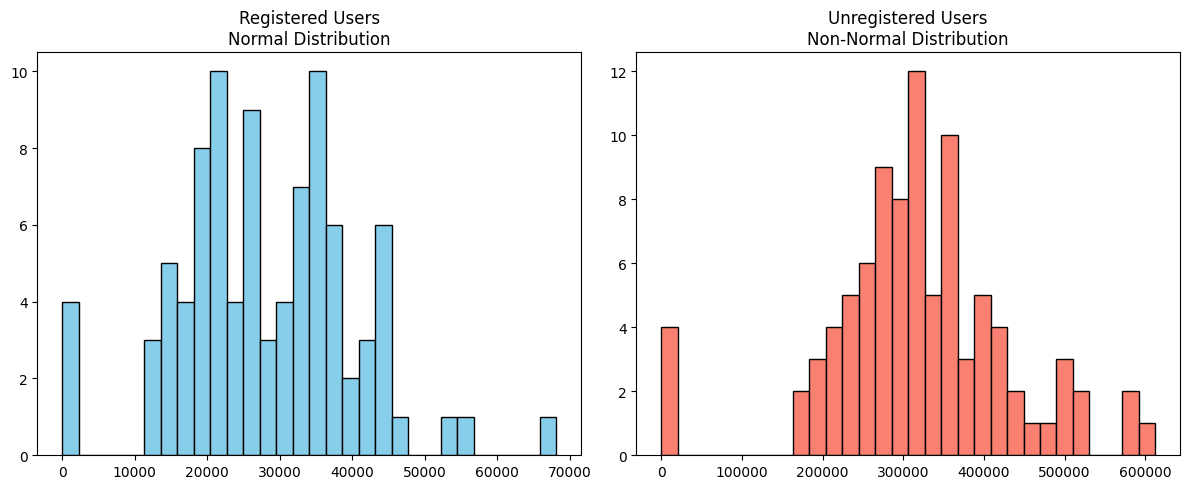

U-statistic: 360.0, p-value: 8.379540669190225e-27
There is a statistically significant difference between the pair.



In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro, mannwhitneyu

# Cleaning order date to only date format without time
df['order_date'] = pd.to_datetime(df['order_date']).dt.date

cols_to_convert = ['session_id', 'registered_user_id']
for col in cols_to_convert:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace({'nan': None, '<NA>': None, 'None': None})

# Create labels for registered and unregistered users
df['user_type'] = df['registered_user_id'].notna().map({True: 'sales_registered', False: 'sales_unregistered'})

# Create pivot table with sum aggregation
df_daily = df.pivot_table(
    index='order_date',
    columns='user_type',
    values='price',
    aggfunc='sum',
    fill_value=0
).reset_index()

# Shapiro-Wilk test
_, p_value_shapiro_registered = shapiro(df_daily['sales_registered'])
_, p_value_shapiro_unregistered = shapiro(df_daily['sales_unregistered'])
print(f"Shapiro-Wilk test for Registered, p-value: {p_value_shapiro_registered}")
print(f"Shapiro-Wilk test for Unregistered, p-value: {p_value_shapiro_unregistered}")

# Plotting histograms to visualize data distributions
plt.figure(figsize=(12, 5))

# Registered subplot
plt.subplot(1, 2, 1)
plt.hist(df_daily['sales_registered'], bins=30, color="skyblue", edgecolor="black")
plt.title("Registered Users\nNormal Distribution")

# Unregistered subplot
plt.subplot(1, 2, 2)
plt.hist(df_daily['sales_unregistered'], bins=30, color="salmon", edgecolor="black")
plt.title("Unregistered Users\nNon-Normal Distribution")

plt.tight_layout()
plt.show()

# Perform Mann-Whitney U test
u_stat, p_value = mannwhitneyu(df_daily['sales_registered'], df_daily['sales_unregistered'])
print(f"U-statistic: {u_stat}, p-value: {p_value}")

if p_value < 0.05:
    print("There is a statistically significant difference between the pair.\n")
else:
    print("No statistically significant difference found between the pair.\n")

#### Key Insights:



1.   Revenue Driver: Unregistered users generate significantly higher daily sales volume (median ~300k PLN/day) compared to registered users (median ~25k PLN/day).
2.   Distribution Characteristics: Sales among registered users follow a normal distribution, whereas unregistered sales exhibit noticeable right-skewness with peak revenue days reaching over 600k PLN.





#### Actionable Recommendations:



*   Conversion Potential: Since unregistered users account for the vast majority of total revenue, focus on introducing friction-free registration incentives (e.g., one-click sign-ups, post-purchase account creation) to convert guest buyers into registered customers.
*   Customer Retention: Investigate why registered users generate a smaller proportion of overall revenue and design targeted loyalty programs to increase their purchase frequency and order values.



### 8.2. Traffic Channel Analysis: Daily Sessions Comparison

In [21]:
import numpy as np
from scipy.stats import shapiro, kruskal

# Cleaning order date to only date format without time
df['order_date'] = pd.to_datetime(df['order_date']).dt.date

# Create pivot table with count aggregation
df_sessions_pivot = df.pivot_table(
    index='order_date',
    columns='traffic_channel',
    values='session_id',
    aggfunc='count'
).fillna(0)

print("Shapiro-Wilk Test for traffic channels")
value = 0.05

for channel in df_sessions_pivot.columns:
    stat, p_val = shapiro(df_sessions_pivot[channel])

    if p_val < value:
        is_normal = "NON-Normal (p < 0.05)"
    else:
        is_normal = "Normal (p >= 0.05)"

    print(f"Channel: {channel:<15} | p-value: {p_val:.3f} -> {is_normal}")

# Perform the Kruskal-Wallis test for every channels
channels_data = [df_sessions_pivot[col] for col in df_sessions_pivot.columns]
stat, p_value = kruskal(*channels_data)

print("\nKRUSKAL-WALLIS TEST RESULTS")
print(f"Kruskal-Wallis statistic: {stat:.4f}")
print(f"P-value: {p_value:.5e}\n")

# Interpretation
if p_value < 0.05:
    print(
        "There is a statistically significant difference in the number of"
        " sessions across traffic channels."
    )
else:
    print(
        "There is no statistically significant difference in the number of"
        " sessions across traffic channels."
    )

Shapiro-Wilk Test for traffic channels
Channel: Direct          | p-value: 0.034 -> NON-Normal (p < 0.05)
Channel: Organic Search  | p-value: 0.012 -> NON-Normal (p < 0.05)
Channel: Paid Search     | p-value: 0.011 -> NON-Normal (p < 0.05)
Channel: Social Search   | p-value: 0.141 -> Normal (p >= 0.05)
Channel: Undefined       | p-value: 0.055 -> Normal (p >= 0.05)

KRUSKAL-WALLIS TEST RESULTS
Kruskal-Wallis statistic: 368.9806
P-value: 1.39704e-78

There is a statistically significant difference in the number of sessions across traffic channels.


#### Key Insights:



1.   Distribution Characteristics: The majority of traffic channels (specifically Direct, Organic Search, and Paid Search) exhibit non-normal daily distributions ($p < 0.05$ in Shapiro-Wilk test), justifying the use of non-parametric testing methods.



#### Actionable Recommendations:



*   Channel Optimization: Focus marketing budget allocation on top-performing channels (Organic and Paid Search) to maximize top-of-funnel reach, while auditing low-performing sources (Social Search) to improve ROI.

